# Credit Card Fraud Detection - Final Notebook
Time-based split, no duplicate encoding, validation-based tuning.

**Changes made after review (each one checked):**
1. Split by the full `trans_date_trans_time` (stable sort), not by `trans_year` (all rows are 2020, so that sort is not chronological).
2. No ordinal encoding before SMOTENC. SMOTENC works on string categories directly.
3. Numeric and categorical lists are kept separate, so nothing goes through both StandardScaler and OneHotEncoder.
4. Chronological train / validation split inside the training period (old data trains, newer data validates).
5. `scale_pos_weight` is tuned on validation (F2 and PR-AUC), not just set to the class ratio.
6. Threshold is searched on the candidate thresholds of `precision_recall_curve`, not a 0.01 grid.
7. The test set is used once, at the end.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (precision_recall_curve, fbeta_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, confusion_matrix, accuracy_score, f1_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
pd.set_option('display.max_columns', None); pd.set_option('display.expand_frame_repr', False)
SEED = 42

## 1. Load data and build the working sample

In [2]:
# Set CSV_PATH to fraudTest.csv. On Kaggle: /kaggle/input/fraud-detection/fraudTest.csv
CSV_PATH = os.environ.get('FRAUD_CSV', '/kaggle/input/fraud-detection/fraudTest.csv')
if not os.path.exists(CSV_PATH):
    import kagglehub
    CSV_PATH = os.path.join(kagglehub.dataset_download('kartik2112/fraud-detection'), 'fraudTest.csv')
df = pd.read_csv(CSV_PATH)
print(df.shape); print(df['is_fraud'].value_counts(normalize=True).mul(100).round(3))

normal = df[df.is_fraud == 0]; fraud = df[df.is_fraud == 1]
data = (pd.concat([normal.sample(n=30000, random_state=SEED), fraud])
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
print(data.shape, data.is_fraud.mean())

(555719, 23)
is_fraud
0    99.614
1     0.386
Name: proportion, dtype: float64


(32145, 23) 0.06672888474101726


## 2. Feature engineering

In [3]:
data['trans_date_trans_time'] = pd.to_datetime(data['trans_date_trans_time'])
data['dob'] = pd.to_datetime(data['dob'])
t = data['trans_date_trans_time']
data['trans_year'] = t.dt.year; data['trans_month'] = t.dt.month; data['trans_day'] = t.dt.day
data['trans_hour'] = t.dt.hour; data['trans_minute'] = t.dt.minute; data['trans_dayofweek'] = t.dt.dayofweek
data['is_weekend'] = (data.trans_dayofweek >= 5).astype(int)
data['is_night'] = ((data.trans_hour >= 22) | (data.trans_hour < 6)).astype(int)

age = t.dt.year - data['dob'].dt.year
not_yet = (t.dt.month < data.dob.dt.month) | ((t.dt.month == data.dob.dt.month) & (t.dt.day < data.dob.dt.day))
data['customer_age'] = age - not_yet.astype(int)

lat1, lon1, lat2, lon2 = map(np.radians, (data.lat, data.long, data.merch_lat, data.merch_long))
a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
data['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
data['log_amt'] = np.log1p(data['amt'])

# Card history features (only PAST transactions of the same card are used)
data = data.sort_values(['cc_num', 'trans_date_trans_time'], kind='stable').reset_index(drop=True)
g = data.groupby('cc_num')
data['time_since_prev_transaction'] = (g['trans_date_trans_time'].diff().dt.total_seconds() / 3600).fillna(-1)
data['previous_transaction_count'] = g.cumcount()
prev = g['amt'].shift(1)
data['amount_difference'] = (data['amt'] - prev).fillna(0)
data['previous_amt'] = prev.fillna(0)
data['amount_ratio_previous'] = data['amt'] / (data['previous_amt'] + 1)

## 3. Chronological train / test split (change 1)
Old code sorted by `trans_year`. All rows are 2020, so every key is equal and the order is not guaranteed.
Now we sort by the full timestamp with a stable sort and assert the order.

In [4]:
data = data.sort_values('trans_date_trans_time', kind='stable').reset_index(drop=True)
time_all = data['trans_date_trans_time'].copy()

drop_cols = ['Unnamed: 0', 'trans_date_trans_time', 'trans_num', 'first', 'last', 'street', 'dob', 'cc_num', 'unix_time']
model_df = data.drop(columns=[c for c in drop_cols if c in data.columns])
X = model_df.drop(columns='is_fraud'); y = model_df['is_fraud']

cut = int(len(X) * 0.80)
X_train, X_test = X.iloc[:cut].copy(), X.iloc[cut:].copy()
y_train, y_test = y.iloc[:cut].copy(), y.iloc[cut:].copy()
t_train, t_test = time_all.iloc[:cut], time_all.iloc[cut:]
assert t_train.is_monotonic_increasing and t_train.max() <= t_test.min(), 'split is not chronological'
print('train', t_train.min(), '->', t_train.max(), '| test', t_test.min(), '->', t_test.max())
print('train fraud %:', round(y_train.mean()*100,2), '| test fraud %:', round(y_test.mean()*100,2))

categorical_features = ['merchant', 'category', 'gender', 'city', 'state', 'job']
numerical_features = [c for c in X_train.columns if c not in categorical_features]
print(len(numerical_features), 'numeric |', len(categorical_features), 'categorical')

train 2020-06-21 12:14:53 -> 2020-12-06 23:04:29 | test 2020-12-06 23:06:23 -> 2020-12-31 23:57:50
train fraud %: 7.59 | test fraud %: 3.0
23 numeric | 6 categorical


## 4. Chronological validation split inside the training period (change 4)
Oldest 80% of the training period fits the model; the newest 20% is the validation set for tuning.

In [5]:
vcut = int(len(X_train) * 0.80)
X_fit, X_val = X_train.iloc[:vcut].copy(), X_train.iloc[vcut:].copy()
y_fit, y_val = y_train.iloc[:vcut].copy(), y_train.iloc[vcut:].copy()
print('fit', X_fit.shape, int(y_fit.sum()), 'frauds | val', X_val.shape, int(y_val.sum()), 'frauds')

fit (20572, 29) 1616 frauds | val (5144, 29) 336 frauds


## 5. SMOTENC on the fit part only, without ordinal encoding (changes 2 and 3)
SMOTENC accepts string categories, so the OrdinalEncoder is removed. The ColumnTransformer then scales only the real numeric columns and one-hot encodes only the 6 categorical columns.

In [6]:
cat_idx = [X_fit.columns.get_loc(c) for c in categorical_features]
smotenc = SMOTENC(categorical_features=cat_idx, k_neighbors=5, sampling_strategy='auto', random_state=SEED)
X_res, y_res = smotenc.fit_resample(X_fit, y_fit)
X_res = pd.DataFrame(X_res, columns=X_fit.columns)
for c in numerical_features: X_res[c] = X_res[c].astype(float)
print('after SMOTENC:', y_res.value_counts().to_dict())

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)])
X_res_p = preprocessor.fit_transform(X_res).astype(np.float32)
X_val_p = preprocessor.transform(X_val).astype(np.float32)
X_test_p = preprocessor.transform(X_test).astype(np.float32)
assert not set(numerical_features) & set(categorical_features)
print('processed:', X_res_p.shape, X_val_p.shape, X_test_p.shape)

after SMOTENC: {0: 18956, 1: 18956}


processed: (37912, 2107) (5144, 2107) (6429, 2107)


## 6. Helper functions

In [7]:
def best_threshold(y_true, prob, beta=2, tol=0.0002):
    # candidates come from precision_recall_curve: every distinct score is a possible cut
    p, r, th = precision_recall_curve(y_true, prob)
    p, r = p[:-1], r[:-1]
    f = (1+beta**2)*p*r / np.maximum(beta**2*p + r, 1e-12)
    ok = np.where(f >= f.max() - tol)[0]           # near-best F2 ...
    i = ok[np.argmax(p[ok])]                        # ... then prefer higher precision
    return float(th[i]), float(f[i])

def metrics(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return dict(Threshold=thr, Accuracy=accuracy_score(y_true, pred), Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred), F2=fbeta_score(y_true, pred, beta=2),
                ROC_AUC=roc_auc_score(y_true, prob), PR_AUC=average_precision_score(y_true, prob), TP=tp, TN=tn, FP=fp, FN=fn)

## 7. Baseline models (default 0.5 threshold, evaluated on validation)

In [8]:
models = {
  'Gaussian Naive Bayes': GaussianNB(),
  'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
  'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=15, max_features='sqrt', random_state=SEED, n_jobs=-1),
  'KNN': KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1),
  'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                           objective='binary:logistic', eval_metric='logloss', random_state=SEED, n_jobs=-1)}
val_prob = {}
rows = []
for name, m in models.items():
    m.fit(X_res_p, y_res); val_prob[name] = m.predict_proba(X_val_p)[:, 1]
    rows.append({'Model': name, **metrics(y_val, val_prob[name], 0.5)})
try:
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Input
    from tensorflow.keras.callbacks import EarlyStopping
    nn = Sequential([Input(shape=(X_res_p.shape[1],)), Dense(64, activation='relu'), Dropout(0.3),
                     Dense(32, activation='relu'), Dropout(0.2), Dense(16, activation='relu'), Dense(1, activation='sigmoid')])
    nn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    nn.fit(X_res_p, y_res, validation_split=0.2, epochs=30, batch_size=256, verbose=0,
           callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
    val_prob['Neural Network'] = nn.predict(X_val_p, verbose=0).ravel()
    rows.append({'Model': 'Neural Network', **metrics(y_val, val_prob['Neural Network'], 0.5)})
except ImportError:
    print('tensorflow not installed - neural network skipped')
display(pd.DataFrame(rows).sort_values('F2', ascending=False).round(4))

I0000 00:00:1793383329.690499     473 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793383343.475278     473 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793383351.621389     473 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC,TP,TN,FP,FN
4,XGBoost,0.5,0.9891,0.9070,0.9286,0.9176,0.9242,0.9964,0.9747,312,4776,32,24
2,Random Forest,0.5,0.9722,0.7383,0.8899,0.8070,0.8548,0.9767,0.8981,299,4702,106,37
1,Logistic Regression,0.5,0.9462,0.5711,0.7054,0.6312,0.6737,0.9210,0.6826,237,4630,178,99
3,KNN,0.5,0.9271,0.4636,0.7381,0.5695,0.6599,0.8947,0.5695,248,4521,287,88
5,Neural Network,0.5,0.9592,0.8281,0.4732,0.6023,0.5176,0.9226,0.7136,159,4775,33,177
0,Gaussian Naive Bayes,0.5,0.8046,0.0059,0.0119,0.0079,0.0099,0.4359,0.0646,4,4135,673,332


## 8. Tune `scale_pos_weight` on validation (change 5)
After SMOTENC the classes are balanced, so the natural weight is 1. Weights above and below are tried; the choice is made on validation F2 (at each weight's own best threshold) and PR-AUC.

In [9]:
base_spw = (y_fit == 0).sum() / (y_fit == 1).sum()
print('raw negative/positive ratio in fit part:', round(base_spw, 3))
grid = [0.5, 1, 2, 4, 8, round(base_spw, 2)]
def make_xgb(spw): 
    return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                         objective='binary:logistic', eval_metric='logloss', scale_pos_weight=spw, random_state=SEED, n_jobs=-1)
res = []
for w in grid:
    m = make_xgb(w).fit(X_res_p, y_res); p = m.predict_proba(X_val_p)[:, 1]
    thr, f2 = best_threshold(y_val, p)
    res.append(dict(scale_pos_weight=w, val_F2=f2, val_PR_AUC=average_precision_score(y_val, p), val_ROC_AUC=roc_auc_score(y_val, p), threshold=thr))
spw_df = pd.DataFrame(res); display(spw_df.round(4))
best = spw_df.sort_values(['val_F2', 'val_PR_AUC'], ascending=False).iloc[0]
best_spw = float(best.scale_pos_weight); print('chosen scale_pos_weight =', best_spw)

raw negative/positive ratio in fit part: 11.73


,scale_pos_weight,val_F2,val_PR_AUC,val_ROC_AUC,threshold
0,0.50,0.9342,0.9742,0.9965,0.2632
1,1.00,0.9339,0.9747,0.9964,0.2947
2,2.00,0.9302,0.9746,0.9963,0.5198
3,4.00,0.9339,0.9755,0.9964,0.4397
4,8.00,0.9335,0.9741,0.9962,0.5227
5,11.73,0.9315,0.9726,0.9962,0.7187


chosen scale_pos_weight = 0.5


## 9. Final model and threshold from precision-recall candidates (change 6)

threshold = 0.2632  (validation F2 = 0.9342)


old 0.01-grid best F2 on validation = 0.9342 at 0.26


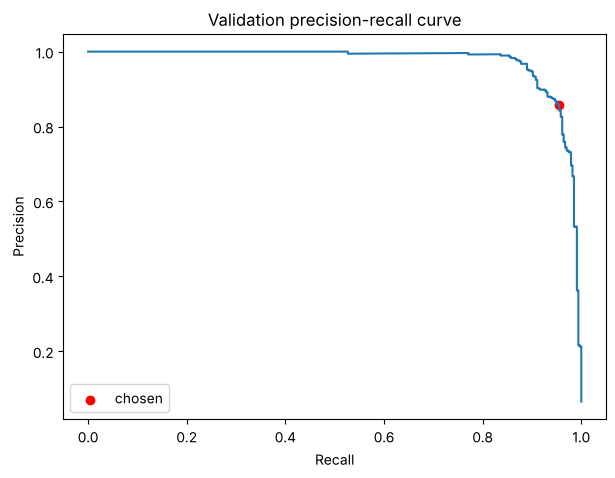

In [10]:
final_model = make_xgb(best_spw).fit(X_res_p, y_res)
pv = final_model.predict_proba(X_val_p)[:, 1]
thr, f2_val = best_threshold(y_val, pv)
print(f'threshold = {thr:.4f}  (validation F2 = {f2_val:.4f})')

# compare with the old 0.01 grid, to show whether the finer search matters
grid_thr = np.arange(0.10, 0.91, 0.01)
f2_grid = [fbeta_score(y_val, pv >= g, beta=2, zero_division=0) for g in grid_thr]
print(f'old 0.01-grid best F2 on validation = {max(f2_grid):.4f} at {grid_thr[int(np.argmax(f2_grid))]:.2f}')

p, r, th = precision_recall_curve(y_val, pv)
plt.figure(figsize=(7, 5)); plt.plot(r, p); plt.scatter(r[np.argmin(abs(th - thr))], p[np.argmin(abs(th - thr))], c='r', label='chosen')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Validation precision-recall curve'); plt.legend(); plt.show()

## 10. One-time evaluation on the untouched test set
Test is the last 20% in time. Threshold and weight were fixed above on validation only.

,Final XGBoost (SMOTENC + tuned weight + PR-threshold)
Threshold,0.2632
Accuracy,0.9830
Precision,0.6448
Recall,0.9689
F1,0.7743
F2,0.8804
ROC_AUC,0.9973
PR_AUC,0.9598
TP,187.0000
TN,6133.0000


missed frauds (FN)  plain XGBoost @0.5: 12 | final: 6
reduction in missed frauds: 50.00%


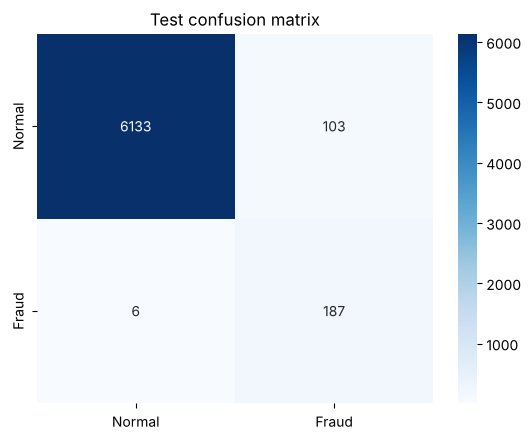

In [11]:
pt = final_model.predict_proba(X_test_p)[:, 1]
final = metrics(y_test, pt, thr)
display(pd.Series(final).round(4).to_frame('Final XGBoost (SMOTENC + tuned weight + PR-threshold)'))

# plain XGBoost with no imbalance handling and threshold 0.5, for "missed frauds" comparison
plain = make_xgb(1).fit(X_fit.pipe(lambda d: preprocessor.transform(d)).astype(np.float32), y_fit)
pp = plain.predict_proba(X_test_p)[:, 1]
plain_m = metrics(y_test, pp, 0.5)
print('missed frauds (FN)  plain XGBoost @0.5:', plain_m['FN'], '| final:', final['FN'])
if plain_m['FN']: print('reduction in missed frauds: %.2f%%' % ((plain_m['FN'] - final['FN']) / plain_m['FN'] * 100))

cm = confusion_matrix(y_test, (pt >= thr).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
plt.title('Test confusion matrix'); plt.show()

## 11. Feature importance

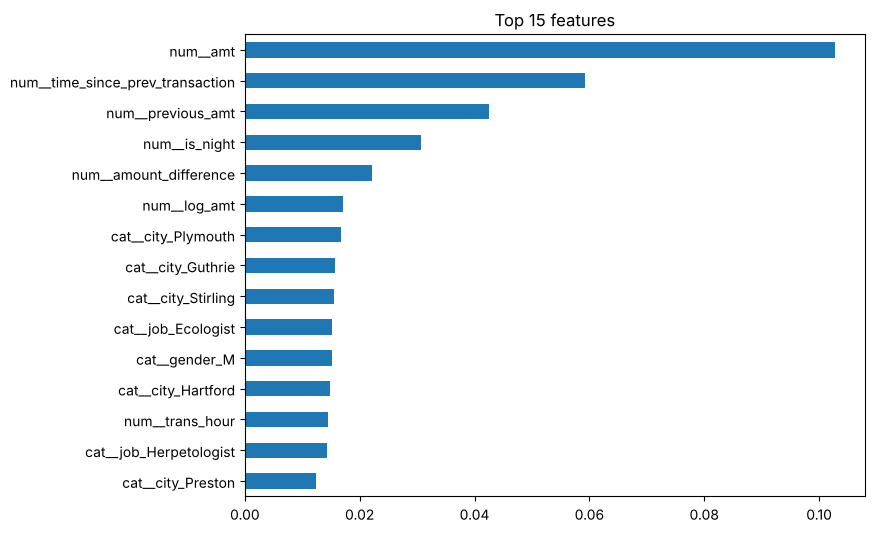

In [12]:
names = preprocessor.get_feature_names_out()
imp = pd.Series(final_model.feature_importances_, index=names).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot.barh(figsize=(8, 6), title='Top 15 features'); plt.show()